# From stimulus to spike: a leaky integrate-and-fire neuron

This notebook is the first computational-neuroscience experiment in this repository. It asks a deliberately narrow question: **how does a time-varying input current alter a simplified membrane voltage and produce discrete spike events?**

Before executing any simulation, write a prediction in `LEARNING_LOG.md`. The model is useful precisely because every line can be related to its equation; it is not a biophysical reconstruction of an action potential.

## The model and a hand calculation

Below threshold, the LIF model is

\[\tau_m \frac{dV}{dt}=-(V-E_L)+R_m I(t).\]

With a constant input, the equilibrium is \(V_\infty=E_L+R_mI\). With the defaults, \(E_L=-65\) mV and \(R_m=100\) MΩ. Predict these values before running the next cell:

- For \(I=0.10\) nA, \(V_\infty=\) ______ mV.
- For \(I=0.30\) nA, \(V_\infty=\) ______ mV.

The threshold is −50 mV. Which input should eventually create spikes in this model?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from neuroai_foundations.lif import LIFParameters, LIFSimulation, simulate_lif

parameters = LIFParameters()
print(parameters)
print(f"Threshold: {parameters.threshold_mv:.1f} mV")

LIFParameters(tau_m_ms=20.0, resistance_mohm=100.0, resting_potential_mv=-65.0, threshold_mv=-50.0, reset_potential_mv=-65.0, refractory_period_ms=2.0)
Threshold: -50.0 mV


In [2]:
def plot_simulation(simulation: LIFSimulation, title: str) -> None:
    """Plot continuous model state, discrete spikes, and the input."""
    figure, (voltage_axis, current_axis) = plt.subplots(
        2, 1, sharex=True, figsize=(10, 5), height_ratios=(3, 1)
    )
    voltage_axis.plot(simulation.time_ms, simulation.voltage_mv, color="navy", lw=1.5)
    voltage_axis.scatter(
        simulation.spike_times_ms,
        simulation.voltage_mv[simulation.spikes],
        color="crimson",
        s=18,
        label="threshold event / reset",
        zorder=3,
    )
    voltage_axis.axhline(parameters.threshold_mv, color="crimson", ls="--", lw=1, label="threshold")
    voltage_axis.axhline(parameters.resting_potential_mv, color="gray", ls=":", lw=1, label="resting potential")
    voltage_axis.set_ylabel("voltage (mV)")
    voltage_axis.set_title(title)
    voltage_axis.legend(loc="best")
    current_axis.plot(simulation.time_ms, simulation.input_current_na, color="darkorange")
    current_axis.set(xlabel="time (ms)", ylabel="current (nA)")
    figure.tight_layout()


def firing_rate_hz(simulation: LIFSimulation) -> float:
    return simulation.spikes.sum() / (simulation.time_ms[-1] / 1_000)

## Experiment 1: constant current

Prediction: zero input should leave the voltage at rest. A weak input whose equilibrium remains below threshold should approach that equilibrium without spiking. A stronger input should cause repeated threshold/reset events.

I = 0.00 nA | predicted equilibrium = -65.0 mV | spikes = 0 | mean rate = 0.0 Hz


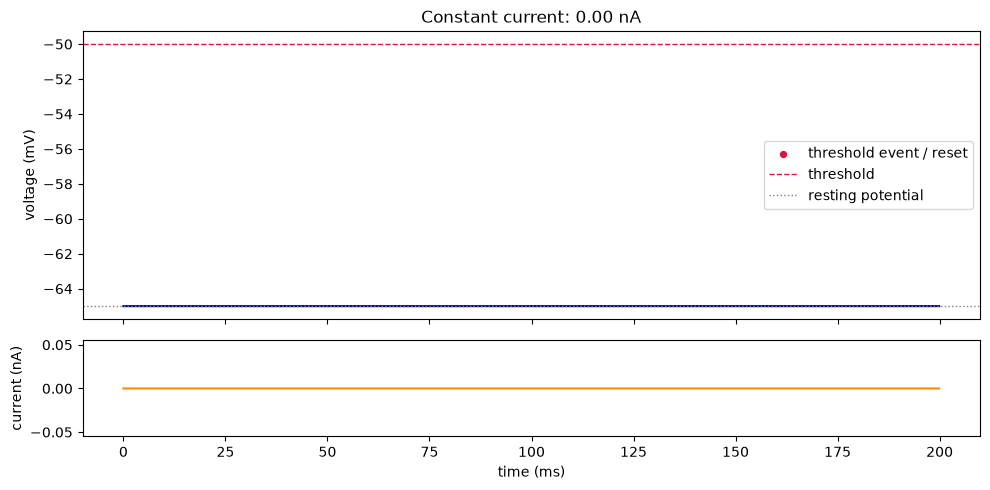

I = 0.10 nA | predicted equilibrium = -55.0 mV | spikes = 0 | mean rate = 0.0 Hz


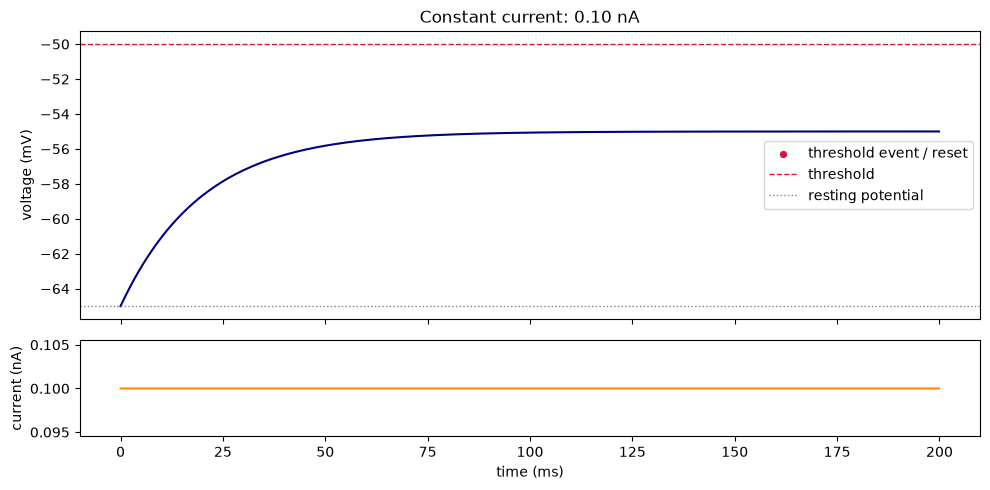

I = 0.20 nA | predicted equilibrium = -45.0 mV | spikes = 6 | mean rate = 30.0 Hz


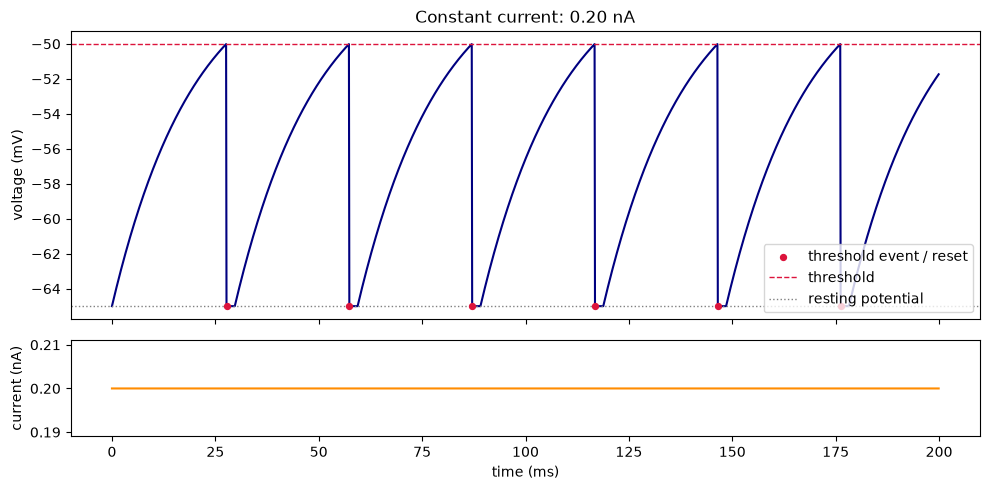

I = 0.30 nA | predicted equilibrium = -35.0 mV | spikes = 12 | mean rate = 60.0 Hz


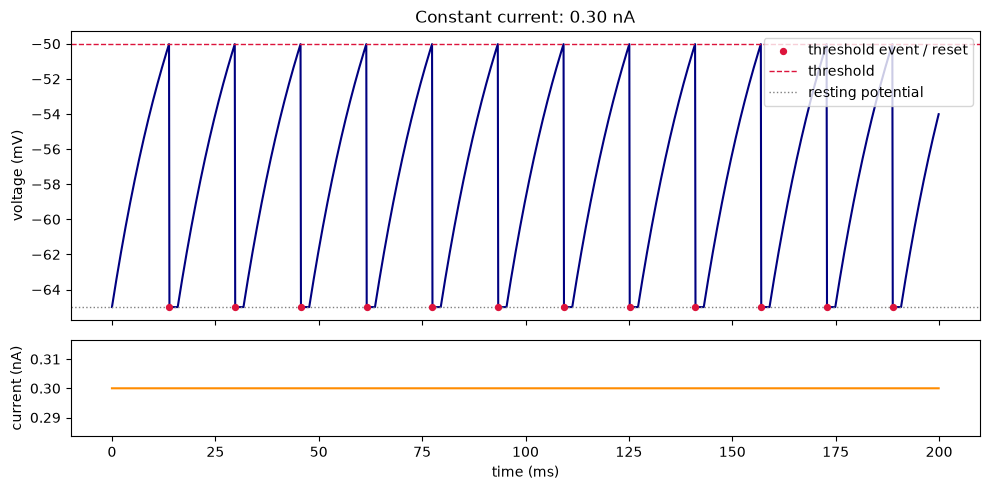

In [3]:
duration_ms = 200.0
dt_ms = 0.1
currents_na = [0.0, 0.10, 0.20, 0.30]

for current_na in currents_na:
    simulation = simulate_lif(current_na, duration_ms=duration_ms, dt_ms=dt_ms, parameters=parameters)
    equilibrium_mv = parameters.resting_potential_mv + parameters.resistance_mohm * current_na
    print(
        f"I = {current_na:.2f} nA | predicted equilibrium = {equilibrium_mv:.1f} mV | "
        f"spikes = {simulation.spikes.sum():d} | mean rate = {firing_rate_hz(simulation):.1f} Hz"
    )
    plot_simulation(simulation, f"Constant current: {current_na:.2f} nA")
    plt.show()

Notice the split between continuous and discrete quantities. The voltage follows a continuous numerical update until the model’s artificial threshold rule converts it into a boolean event. The red points are reset voltages, not realistic spike waveforms.

## Experiment 2: a transient stimulus

Predict what happens after the pulse ends. Does the model retain a permanent voltage increase, or does the leak term pull it toward rest? If it spikes during the pulse, can it continue spiking after the input is removed?

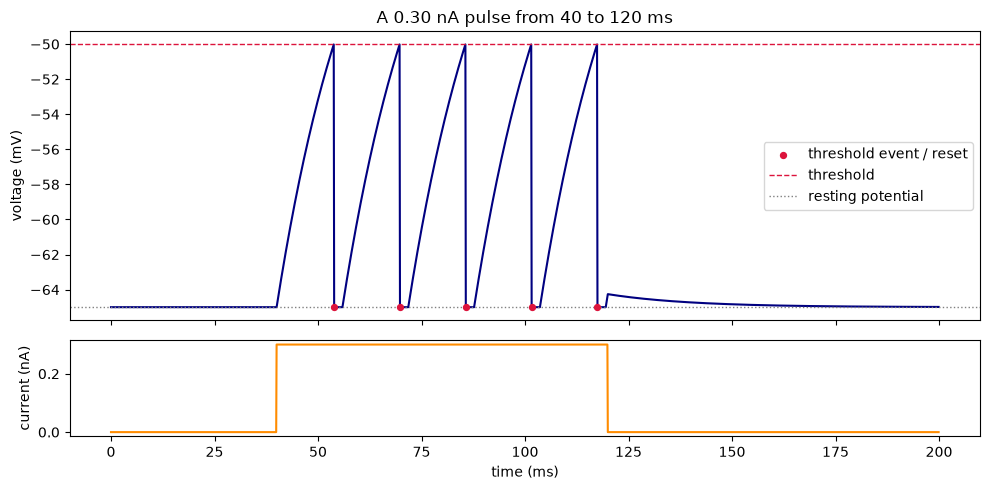

Spikes during entire trial: 5
Spikes after pulse end: 0


In [4]:
n_steps = int(duration_ms / dt_ms)
pulse_current_na = np.zeros(n_steps)
pulse_start_ms, pulse_end_ms = 40.0, 120.0
pulse_current_na[int(pulse_start_ms / dt_ms) : int(pulse_end_ms / dt_ms)] = 0.30

pulse_simulation = simulate_lif(
    pulse_current_na, duration_ms=duration_ms, dt_ms=dt_ms, parameters=parameters
)
plot_simulation(pulse_simulation, "A 0.30 nA pulse from 40 to 120 ms")
plt.show()

after_pulse = pulse_simulation.spike_times_ms > pulse_end_ms
print(f"Spikes during entire trial: {pulse_simulation.spikes.sum()}")
print(f"Spikes after pulse end: {after_pulse.sum()}")

## Interpretation and limits

This simulation demonstrates an explicit hypothesis: a leaky threshold unit can transform the amplitude and timing of an injected current into a sequence of events. It does **not** establish that a biological neuron encodes a stimulus this way. Real neurons have ion channels, synaptic reversal potentials, spatial structure, noise, adaptation, and many other mechanisms that this model deliberately excludes.

For the next milestone, do the exercises in the companion README and record: (1) your predictions, (2) what changed, and (3) whether the result followed from the equation. Do not proceed merely because the plots look plausible.